# Poisson rates at active boundaries

Zero counts permit exact zero-rate optima. The supplied second day is validation, while the synthetic studies reserve an independent test day. Strict infinite likelihood and the declared predictive floor are reported separately.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## Boundary oracle

In [2]:
from optimization_lab.first_order import poisson_prox,poisson_smooth
assert poisson_prox(.5,0.,1.)==0.
result=poisson_smooth([0,4,0,2],0.)
assert np.allclose(result["rate"],[0,4,0,2],atol=1e-5)
print(result["rate"],result["kkt_residual"])

[0.         4.00000035 0.         2.        ] 8.792217620623433e-08


## Validation and test roles

In [3]:
rows=[]
for label in ["original","synthetic_seed0","synthetic_seed1","synthetic_seed2"]:
    m=read(f"results/reference/first_order/poisson_{label}/metrics.json")
    rows.append(dict(task=label,**m["selected"]))
pd.DataFrame(rows)

,task,rho,validation,independent_test
0,original,1,"{'strict_nll': 37.74828674214574, 'strict_nll_...",None
1,synthetic_seed0,10,"{'strict_nll': 71.89429625600488, 'strict_nll_...","{'strict_nll': 63.01095873296839, 'strict_nll_..."
2,synthetic_seed1,10,"{'strict_nll': 72.93205216817995, 'strict_nll_...","{'strict_nll': 81.27903643101784, 'strict_nll_..."
3,synthetic_seed2,10,"{'strict_nll': 81.60142843310162, 'strict_nll_...","{'strict_nll': 78.77017390305468, 'strict_nll_..."


## Original counts and validation selection

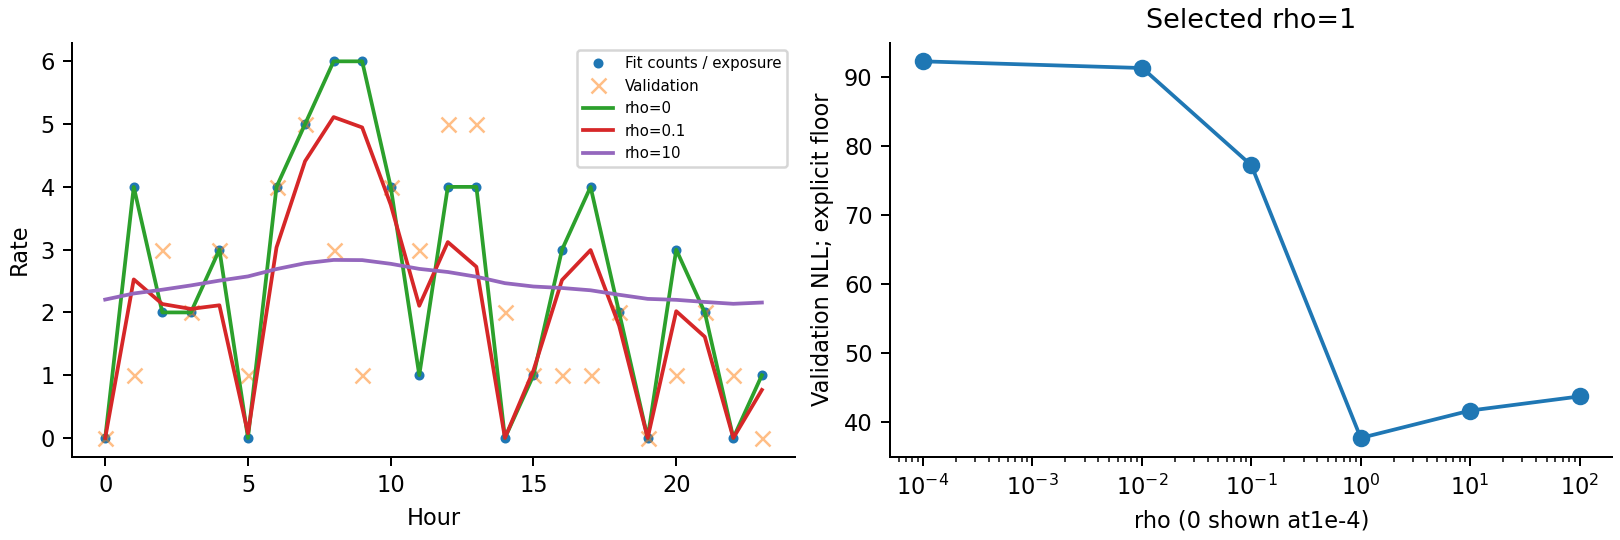

In [4]:
figure("poisson_original")

## Independent synthetic task

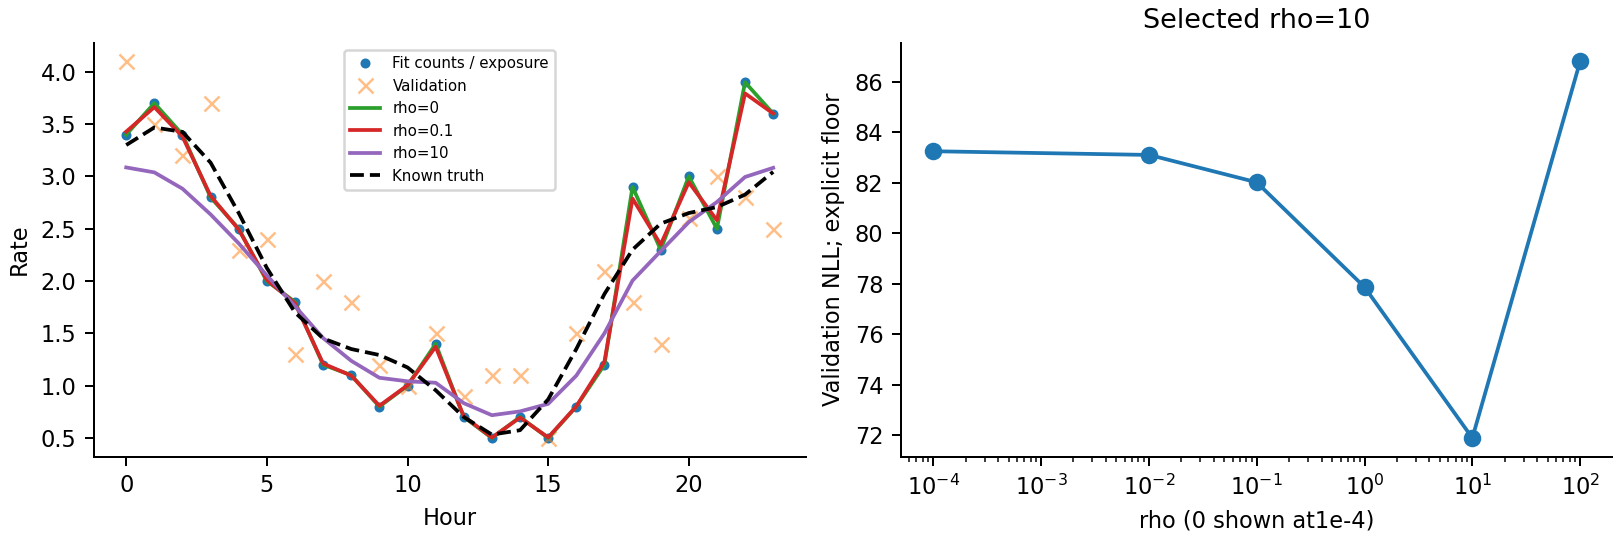

In [5]:
figure("poisson_synthetic_seed0")

Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.